# N164 · Learn delayed action effects from paired online feedback

Use both N161 BDD development pools and three training RNG seeds. The warm MAE,
current-image training recipe, stream order, and 128-arrival context are shared.
Each trajectory gets 15,232 arrivals. Reuse the completed N161 quarter-rate
references for the first seed and train quarter-rate controls for two more seeds.

Four controllers combine base/gradient-preview features with loss-only/loss-plus-
health selection. Every 16 arrivals choose skip, quarter or nominal, then use
quarter between decisions. Predict the difference from quarter in mean incoming
pre-update loss over the following 16 arrivals. Measure RankMe and variance by
re-encoding those same 16 images at the end of the window, before the next rate
decision. Each image becomes available in arrival order.

Every 128 arrivals, copy the learner AND AdamW into the two alternative rate
branches. Reveal each new image to all branches together. Use the same fixed loss
masks and training seeds, with common quarter-rate continuation. After 16 arrivals
score the forecasts, then update the feature-dependent coefficients of BOTH rate
effect heads. Quarter effects are exactly zero. A separate shared outcome head
learns from paired quarter outcomes and factual quarter windows.

Offline fitting, calibration and testing use disjoint archived clips. Each split
has three seeded quarter reference paths. Freeze the health tolerance at the
75th percentile of absolute relative RankMe effects in calibration. Subtract each
model/rate's nonnegative 80th percentile rank overprediction margin. A guarded
alternative must predict lower loss and have its RankMe lower bound above the
negative tolerance. Quarter is always available. Every rate decision and gate is
logged. The objective contains predicted incoming loss.

After each controller, run a retrospective randomized schedule with the same rate
counts in every 12 decision opportunities. These controls use the realized budgets
of that controller. They are comparisons of timing at matched work. Identical
random schedules share a trajectory. Rate budgets are outcomes of the policies.

Record every offered image's pre-update loss, actual loss on every trained image,
contextual RankMe and variance, independent fixed day/night audit health, delayed
absolute forecast RMSE against persistence, paired effect RMSE against zero, and
simple next-arrival H1 RMSE. Count preview backward passes, extra branch updates
and their elapsed time. Compare each controller with quarter and its own matched
random schedule in all six pool/seed combinations. The pools are development data.

Checkpoints include pending branch models, optimizers, measured partial windows,
and predictor states. The notebook publishes every 15 seconds. Reserve 3 GiB
of disk space. A watchdog requests idle-sleep prevention and recovers interrupted
processes from the saved state.


## Stopped-run findings and interpretation

Stopped at the user's request on 8 November 2026. The runner and watchdog exited. The saved checkpoint includes the last committed partial trajectory.

Coverage includes 31 newly completed trajectories, two reused quarter-rate references, and 14 of 24 planned controller/random comparisons. Fifteen controller trajectories completed. The unfinished matched random trajectory is saved at 4,480/15,232 arrivals. The third seed was not started.

Descriptive averages below use complete matched pairs only. Base variants have both pools under two seeds. Preview variants have both pools under the first seed and pool 1 under the second. Preview averages consequently give pool 1 more weight. These are development results, and the experiment stopped before its planned replication completed.

| Controller | Complete pairs | Incoming gain vs quarter | Incoming gain vs matched random | Stream RankMe difference vs random |
|---|---:|---:|---:|---:|
| base_loss | 4 | +0.001120 | +0.000004 | -0.00348 |
| base_guard | 4 | -0.000418 | -0.000357 | +0.00493 |
| preview_loss | 3 | +0.001529 | +0.000823 | +0.04251 |
| preview_guard | 3 | -0.000889 | +0.000009 | +0.01771 |

Positive loss gains mean lower pre-update loss on incoming images. Every random control matches the controller's actual rates within each group of 12 decision slots. Rate counts are fixed retrospectively for this timing diagnostic.

For balanced coverage, the first seed across both pools gives incoming-loss gains versus matched random of +0.000046 for base loss, +0.000092 for base guard, +0.000794 for preview loss, and -0.000173 for preview guard.

The loss-only policies spent about 16% more LR dose than always-quarter. Their gains versus quarter combine rate exposure and timing. Base loss selected full rate at about 91% of decision opportunities, while preview loss selected it at about 87%. A simple periodic full-rate schedule is therefore a necessary comparator.

Preview loss has the strongest timing evidence. Its completed matched gains were +0.001632 and +0.000882 in pool 1 under the first two seeds, and -0.000044 in pool 2 under the first seed. Its second pool / second seed controller beat quarter by +0.000545, but its matched random control was interrupted, so no final timing comparison is available for that case. The apparent benefit is concentrated in pool 1.

Health effects were inconsistent across populations and seeds. Preview loss improved stream RankMe versus its matched random control in all three completed pairs, but it did not consistently improve RankMe relative to always-quarter. Final audit outcomes also varied between pools and seeds.

| Controller | Paired loss-effect RMSE reduction vs zero | RankMe-effect RMSE reduction vs zero | Variance-effect RMSE reduction vs zero |
|---|---:|---:|---:|
| base_loss | +20.3% | -1.9% | -0.3% |
| base_guard | +19.9% | -5.1% | -0.1% |
| preview_loss | +32.4% | -2.6% | -0.6% |
| preview_guard | +34.2% | -3.6% | -1.1% |

These error aggregates use all completed controller trajectories, including the fourth preview-loss trajectory whose random control is incomplete. Forecasts were recorded before feedback. The predictor learned its feature coefficients from 119 matured paired windows per completed controller.

Loss-effect prediction improved, especially with gradient preview. RankMe-effect forecasts remained worse than predicting zero change. The calibrated guard allowed 0.222% relative RankMe degradation with a one-sided forecast margin. It selected quarter for most opportunities, and its loss cost was not accompanied by a consistent improvement over matched controls.

The guard targets RankMe on 16 consecutive incoming frames re-encoded at the end of the window. The stream plots use an eight-image context, and the independent audit uses 48 frames per lighting condition. These populations have different diversity and sample-size limits. Sixteen correlated frames provide a limited representation-health signal for 96-dimensional embeddings.

A short repeated benchmark using identical states and actions measured about 15% more elapsed processing time, 13% lower throughput, and 12.6 MiB additional model/optimizer/gradient tensor storage for paired copies. This measurement was taken on the current CPU while the experiment ran and is not a target-edge hardware measurement. The preview gradient is reused on accepted updates.

Recommended next design

1. Use one live learner and a small action-conditioned predictor of mean incoming pre-update loss over the following 16 arrivals. Obtain paired supervision offline or during occasional development diagnostics. Evaluate online adaptation from factual delayed outcomes and logged randomized choices under the actual edge compute budget.
2. First reuse the saved paired data for a compact prediction screen. Compare the 14-feature model, gradient-preview features, and simple per-rate mean-effect predictions using clip-grouped held-out evaluation. Score action ranking and realized selection gain as well as RMSE. A bank-history or bank-change feature ablation can test transfer to incoming loss directly. Separate independent ridge outputs alone do not create parameter sharing between tasks.
3. Compare closed-loop control with always-quarter, a periodic higher-rate schedule at the same budget, and a randomized schedule with matching rates. Fix update/dose or wall-time/energy budgets explicitly. Require repeatable incoming-loss improvement across both pools before a larger replication.
4. Validate health on a larger temporally spaced panel of already-seen images, with identical membership across compared model states, plus the independent audit. Calibrate a measured-health safeguard after validating its relationship with representation retention. Use the local 16-frame RankMe readout as a local diagnostic while that validation proceeds.

The decision-focused evaluation principle is consistent with [Smart Predict, then Optimize](https://arxiv.org/abs/1710.08005). The specific engineering choices above are recommendations based on N164.

## Live status

**paused** · Stopped at user request. Last checkpoint seed_1/pool_2/random_preview_loss, 4,480/15,232 arrivals.

Updated UTC `2026-11-07T23:22:49+00:00` · PID `37196`.

Stopped at your request.

Free disk **13.8 GiB** with a 3 GiB reserve.

Calibrated relative RankMe degradation tolerance **0.222%**.

## Held-out action effects

RMSE is predictor / zero effect. Positive gain favors the selector over matched random.

| Features | Origins | Loss RMSE | Relative RankMe RMSE | Loss selector gain | Guard selector gain |
|---|---:|---:|---:|---:|---:|
| base | 117 | 0.0029821 / 0.0031574 | 0.0035079 / 0.003473 | -0.000160 | -0.000127 |
| preview | 117 | 0.0024626 / 0.0031574 | 0.0033667 / 0.003473 | +0.000187 | +0.000080 |

## Measured trajectories

| Seed / pool / arm | Images | Incoming loss | RankMe | Training loss | Skip / quarter / full | Paired labels |
|---|---:|---:|---:|---:|---:|---:|
| seed_0/pool_1/reused_quarter | 15,232 | 0.794880 | 1.51785 | 0.77578 | 0 / 15232 / 0 | 0 |
| seed_0/pool_1/base_loss | 15,232 | 0.794263 | 1.51775 | 0.77702 | 78 / 14324 / 830 | 119 |
| seed_0/pool_1/random_base_loss | 15,232 | 0.793917 | 1.54032 | 0.77627 | 78 / 14324 / 830 | 0 |
| seed_0/pool_1/base_guard | 15,232 | 0.795522 | 1.53093 | 0.77703 | 32 / 15195 / 5 | 119 |
| seed_0/pool_1/random_base_guard | 15,232 | 0.795551 | 1.51362 | 0.77667 | 32 / 15195 / 5 | 0 |
| seed_0/pool_1/preview_loss | 15,232 | 0.793773 | 1.54419 | 0.77610 | 57 / 14369 / 806 | 119 |
| seed_0/pool_1/random_preview_loss | 15,232 | 0.795405 | 1.51378 | 0.77784 | 57 / 14369 / 806 | 0 |
| seed_0/pool_1/preview_guard | 15,232 | 0.795488 | 1.54070 | 0.77708 | 50 / 15142 / 40 | 119 |
| seed_0/pool_1/random_preview_guard | 15,232 | 0.794710 | 1.52518 | 0.77599 | 50 / 15142 / 40 | 0 |
| seed_0/pool_2/reused_quarter | 15,232 | 0.831038 | 1.57302 | 0.81085 | 0 / 15232 / 0 | 0 |
| seed_0/pool_2/base_loss | 15,232 | 0.829454 | 1.51844 | 0.81022 | 43 / 14323 / 866 | 119 |
| seed_0/pool_2/random_base_loss | 15,232 | 0.829891 | 1.51458 | 0.81028 | 43 / 14323 / 866 | 0 |
| seed_0/pool_2/base_guard | 15,232 | 0.830962 | 1.57443 | 0.81138 | 58 / 15169 / 5 | 119 |
| seed_0/pool_2/random_base_guard | 15,232 | 0.831116 | 1.57500 | 0.81114 | 58 / 15169 / 5 | 0 |
| seed_0/pool_2/preview_loss | 15,232 | 0.829614 | 1.55169 | 0.80994 | 20 / 14392 / 820 | 119 |
| seed_0/pool_2/random_preview_loss | 15,232 | 0.829570 | 1.51453 | 0.80983 | 20 / 14392 / 820 | 0 |
| seed_0/pool_2/preview_guard | 15,232 | 0.830874 | 1.57085 | 0.81089 | 41 / 15145 / 46 | 119 |
| seed_0/pool_2/random_preview_guard | 15,232 | 0.831308 | 1.56909 | 0.81115 | 41 / 15145 / 46 | 0 |
| seed_1/pool_1/quarter | 15,232 | 0.793456 | 1.54117 | 0.77643 | 0 / 15232 / 0 | 0 |
| seed_1/pool_1/base_loss | 15,232 | 0.791529 | 1.52942 | 0.77527 | 34 / 14316 / 882 | 119 |
| seed_1/pool_1/random_base_loss | 15,232 | 0.791595 | 1.52365 | 0.77488 | 34 / 14316 / 882 | 0 |
| seed_1/pool_1/base_guard | 15,232 | 0.794483 | 1.54961 | 0.77765 | 33 / 15193 / 6 | 119 |
| seed_1/pool_1/random_base_guard | 15,232 | 0.793680 | 1.54996 | 0.77686 | 33 / 15193 / 6 | 0 |
| seed_1/pool_1/preview_loss | 15,232 | 0.791400 | 1.51787 | 0.77481 | 25 / 14366 / 841 | 119 |
| seed_1/pool_1/random_preview_loss | 15,232 | 0.792282 | 1.45790 | 0.77541 | 25 / 14366 / 841 | 0 |
| seed_1/pool_1/preview_guard | 15,232 | 0.795679 | 1.52104 | 0.77906 | 52 / 15147 / 33 | 119 |
| seed_1/pool_1/random_preview_guard | 15,232 | 0.796051 | 1.48517 | 0.77942 | 52 / 15147 / 33 | 0 |
| seed_1/pool_2/quarter | 15,232 | 0.831907 | 1.55235 | 0.81185 | 0 / 15232 / 0 | 0 |
| seed_1/pool_2/base_loss | 15,232 | 0.831554 | 1.50753 | 0.81202 | 39 / 14315 / 878 | 119 |
| seed_1/pool_2/random_base_loss | 15,232 | 0.831414 | 1.50853 | 0.81168 | 39 / 14315 / 878 | 0 |
| seed_1/pool_2/base_guard | 15,232 | 0.831986 | 1.54593 | 0.81254 | 56 / 15170 / 6 | 119 |
| seed_1/pool_2/random_base_guard | 15,232 | 0.831176 | 1.54261 | 0.81169 | 56 / 15170 / 6 | 0 |
| seed_1/pool_2/preview_loss | 15,232 | 0.831363 | 1.50882 | 0.81152 | 13 / 14383 / 836 | 119 |
| seed_1/pool_2/random_preview_loss | 4,480 | 0.865935 | 1.46844 | 0.84526 | 4 / 4225 / 251 | 0 |

## Forecast errors

Entries show forecast / persistence or zero effect.

| Controller | H16 loss | Loss effect | RankMe effect | Variance effect | Preview backwards | Branch updates |
|---|---:|---:|---:|---:|---:|---:|
| seed_0/pool_1/base_loss | 0.048884 / 0.078818 | 0.0033042 / 0.0042736 | 0.0047449 / 0.0046392 | 0.05666 / 0.056024 | 0 | 3700 |
| seed_0/pool_1/random_base_loss | — | — | — | — | 0 | 0 |
| seed_0/pool_1/base_guard | 0.042735 / 0.074685 | 0.0031289 / 0.0041111 | 0.0020649 / 0.001917 | 0.031021 / 0.030928 | 0 | 3694 |
| seed_0/pool_1/random_base_guard | — | — | — | — | 0 | 0 |
| seed_0/pool_1/preview_loss | 0.04723 / 0.078519 | 0.0029011 / 0.00453 | 0.0043897 / 0.0043608 | 0.065896 / 0.065949 | 951 | 3694 |
| seed_0/pool_1/random_preview_loss | — | — | — | — | 0 | 0 |
| seed_0/pool_1/preview_guard | 0.041263 / 0.073314 | 0.0021841 / 0.0034375 | 0.0047763 / 0.0047484 | 0.054961 / 0.054805 | 951 | 3692 |
| seed_0/pool_1/random_preview_guard | — | — | — | — | 0 | 0 |
| seed_0/pool_2/base_loss | 0.054262 / 0.080403 | 0.00271 / 0.0033037 | 0.0032348 / 0.0031883 | 0.039627 / 0.039775 | 0 | 3695 |
| seed_0/pool_2/random_base_loss | — | — | — | — | 0 | 0 |
| seed_0/pool_2/base_guard | 0.050424 / 0.079167 | 0.0025321 / 0.0030934 | 0.0025883 / 0.0025061 | 0.027293 / 0.027371 | 0 | 3697 |
| seed_0/pool_2/random_base_guard | — | — | — | — | 0 | 0 |
| seed_0/pool_2/preview_loss | 0.053632 / 0.081094 | 0.0022551 / 0.0032204 | 0.0050655 / 0.0048836 | 0.039629 / 0.037919 | 951 | 3693 |
| seed_0/pool_2/random_preview_loss | — | — | — | — | 0 | 0 |
| seed_0/pool_2/preview_guard | 0.049807 / 0.079401 | 0.0021676 / 0.0030768 | 0.0023369 / 0.00214 | 0.027401 / 0.026724 | 951 | 3697 |
| seed_0/pool_2/random_preview_guard | — | — | — | — | 0 | 0 |
| seed_1/pool_1/quarter | — | — | — | — | 0 | 0 |
| seed_1/pool_1/base_loss | 0.047261 / 0.075616 | 0.0027448 / 0.0036221 | 0.0020208 / 0.0018742 | 0.031261 / 0.030705 | 0 | 3693 |
| seed_1/pool_1/random_base_loss | — | — | — | — | 0 | 0 |
| seed_1/pool_1/base_guard | 0.0424 / 0.072474 | 0.0027568 / 0.0034772 | 0.0017492 / 0.0015872 | 0.027478 / 0.027394 | 0 | 3693 |
| seed_1/pool_1/random_base_guard | — | — | — | — | 0 | 0 |
| seed_1/pool_1/preview_loss | 0.045932 / 0.075365 | 0.0023148 / 0.0036014 | 0.00227 / 0.0020018 | 0.031537 / 0.030573 | 951 | 3692 |
| seed_1/pool_1/random_preview_loss | — | — | — | — | 0 | 0 |
| seed_1/pool_1/preview_guard | 0.042018 / 0.07421 | 0.0020357 / 0.0031883 | 0.0028919 / 0.0026465 | 0.045589 / 0.044743 | 951 | 3693 |
| seed_1/pool_1/random_preview_guard | — | — | — | — | 0 | 0 |
| seed_1/pool_2/quarter | — | — | — | — | 0 | 0 |
| seed_1/pool_2/base_loss | 0.054216 / 0.081114 | 0.002892 / 0.0033898 | 0.0059875 / 0.0059151 | 0.076927 / 0.077076 | 0 | 3695 |
| seed_1/pool_2/random_base_loss | — | — | — | — | 0 | 0 |
| seed_1/pool_2/base_guard | 0.050393 / 0.079642 | 0.0028452 / 0.0033311 | 0.0030373 / 0.0029267 | 0.032857 / 0.032799 | 0 | 3698 |
| seed_1/pool_2/random_base_guard | — | — | — | — | 0 | 0 |
| seed_1/pool_2/preview_loss | 0.055225 / 0.081292 | 0.0025268 / 0.0033797 | 0.0057931 / 0.0057134 | 0.080825 / 0.080936 | 951 | 3692 |
| seed_1/pool_2/random_preview_loss | 4,480 | 0.865935 | 1.46844 | 0.84526 | 4 / 4225 / 251 | 0 |

## Completed matched comparisons

Positive loss gains favor the controller. Each row requires complete matching runs.

| Seed / pool / controller | Incoming gain vs quarter | Incoming gain vs random | RankMe vs random | Audit loss gain vs random |
|---|---:|---:|---:|---:|
| seed_0/pool_1/base_loss | +0.000617 | -0.000346 | -0.02256 | -0.069453 |
| seed_0/pool_1/base_guard | -0.000642 | +0.000029 | +0.01731 | -0.058213 |
| seed_0/pool_1/preview_loss | +0.001107 | +0.001632 | +0.03041 | +0.165771 |
| seed_0/pool_1/preview_guard | -0.000608 | -0.000778 | +0.01551 | -0.002967 |
| seed_0/pool_2/base_loss | +0.001584 | +0.000437 | +0.00386 | +0.010920 |
| seed_0/pool_2/base_guard | +0.000076 | +0.000154 | -0.00057 | +0.008679 |
| seed_0/pool_2/preview_loss | +0.001424 | -0.000044 | +0.03716 | -0.009428 |
| seed_0/pool_2/preview_guard | +0.000163 | +0.000433 | +0.00176 | +0.026813 |
| seed_1/pool_1/base_loss | +0.001927 | +0.000066 | +0.00577 | +0.027529 |
| seed_1/pool_1/base_guard | -0.001026 | -0.000803 | -0.00035 | +0.047736 |
| seed_1/pool_1/preview_loss | +0.002056 | +0.000882 | +0.05997 | +0.004583 |
| seed_1/pool_1/preview_guard | -0.002223 | +0.000372 | +0.03587 | +0.023607 |
| seed_1/pool_2/base_loss | +0.000353 | -0.000140 | -0.00100 | -0.011187 |
| seed_1/pool_2/base_guard | -0.000078 | -0.000809 | +0.00332 | +0.036217 |

### Actual incoming loss and health

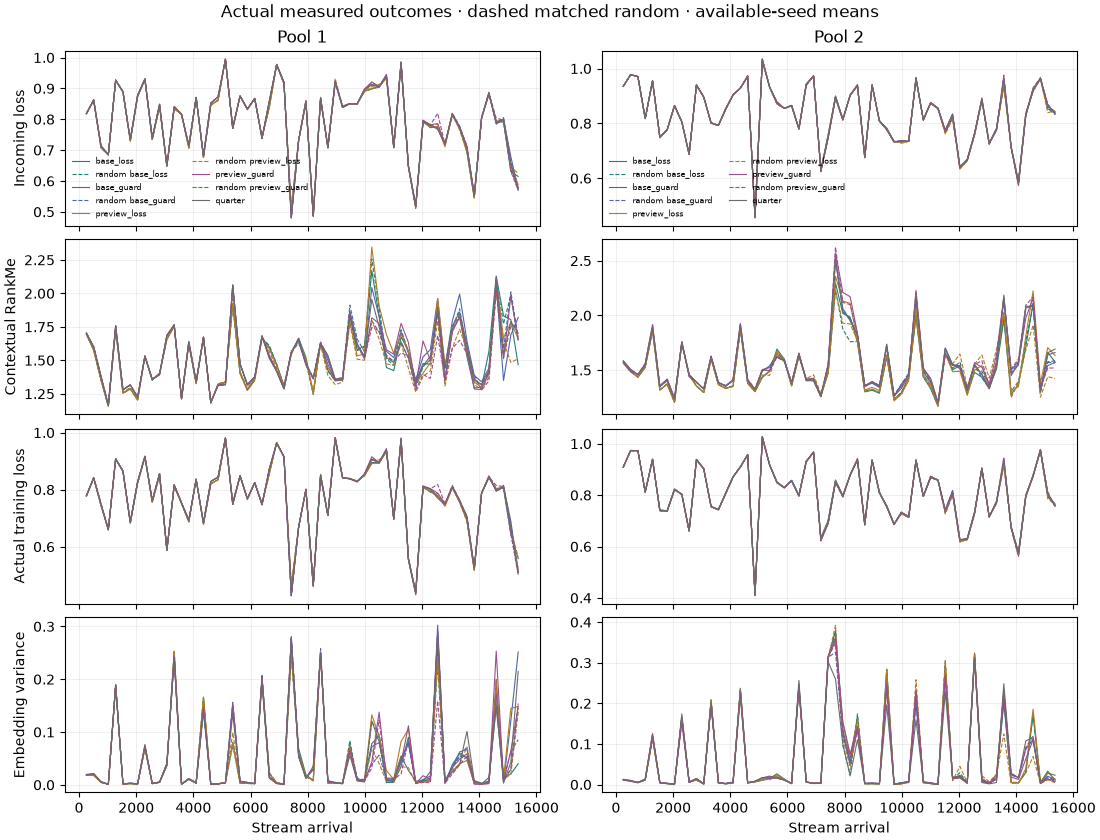

### Paired effect forecast RMSE

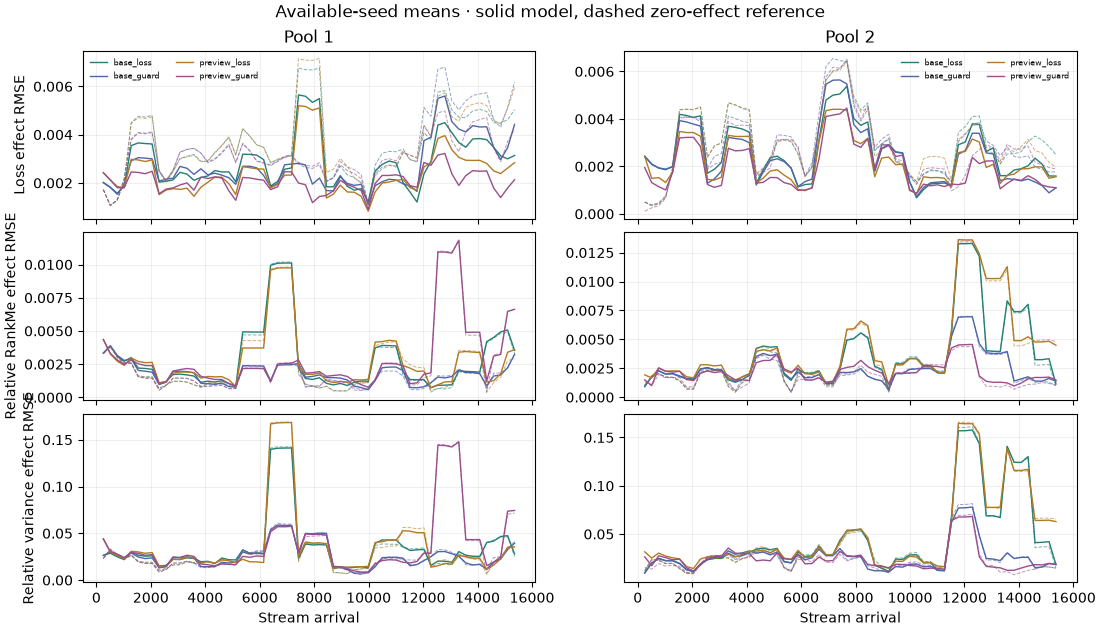